In [4]:
!pip install earthengine-api geemap -q

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
ee.Authenticate()
ee.Initialize(project='urban-heat-mitigation-510914')  # your GEE project id

In [6]:
CITIES = {
    "Pune":       {"lat": 18.5204, "lon": 73.8567, "box_km": 22},
    "Hyderabad":  {"lat": 17.3850, "lon": 78.4867, "box_km": 25},
    "Ahmedabad":  {"lat": 23.0225, "lon": 72.5714, "box_km": 22},
    "Delhi":      {"lat": 28.6139, "lon": 77.2090, "box_km": 25},
    "Nagpur":     {"lat": 21.1458, "lon": 79.0882, "box_km": 20},
}

DATE_WINDOW = ("2025-04-01", "2025-05-31")
CLOUD_MAX = 10

def city_bbox(lat, lon, box_km):
    deg = box_km / 111.0
    return ee.Geometry.Rectangle([lon - deg/2, lat - deg/2, lon + deg/2, lat + deg/2])

In [7]:
raw_images = {}   # city -> (ee.Image, region)

for city, cfg in CITIES.items():
    region = city_bbox(cfg["lat"], cfg["lon"], cfg["box_km"])

    collection = (ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')
                  .filterBounds(region)
                  .filterDate(DATE_WINDOW[0], DATE_WINDOW[1])
                  .filter(ee.Filter.lt('CLOUD_COVER', CLOUD_MAX))
                  .sort('CLOUD_COVER'))

    count = collection.size().getInfo()
    if count == 0:
        print(f"{city}: NO clear scene found — widen date range/cloud threshold")
        continue

    image = ee.Image(collection.first())
    cloud_pct = image.get('CLOUD_COVER').getInfo()
    date = image.date().format('YYYY-MM-dd').getInfo()

    raw_images[city] = (image, region)
    print(f"{city}: scene date={date}, cloud_cover={cloud_pct}%")

Pune: scene date=2025-04-27, cloud_cover=0.24%
Hyderabad: scene date=2025-04-22, cloud_cover=0.19%
Ahmedabad: scene date=2025-04-18, cloud_cover=0%
Delhi: scene date=2025-04-04, cloud_cover=0.01%
Nagpur: scene date=2025-04-06, cloud_cover=0%


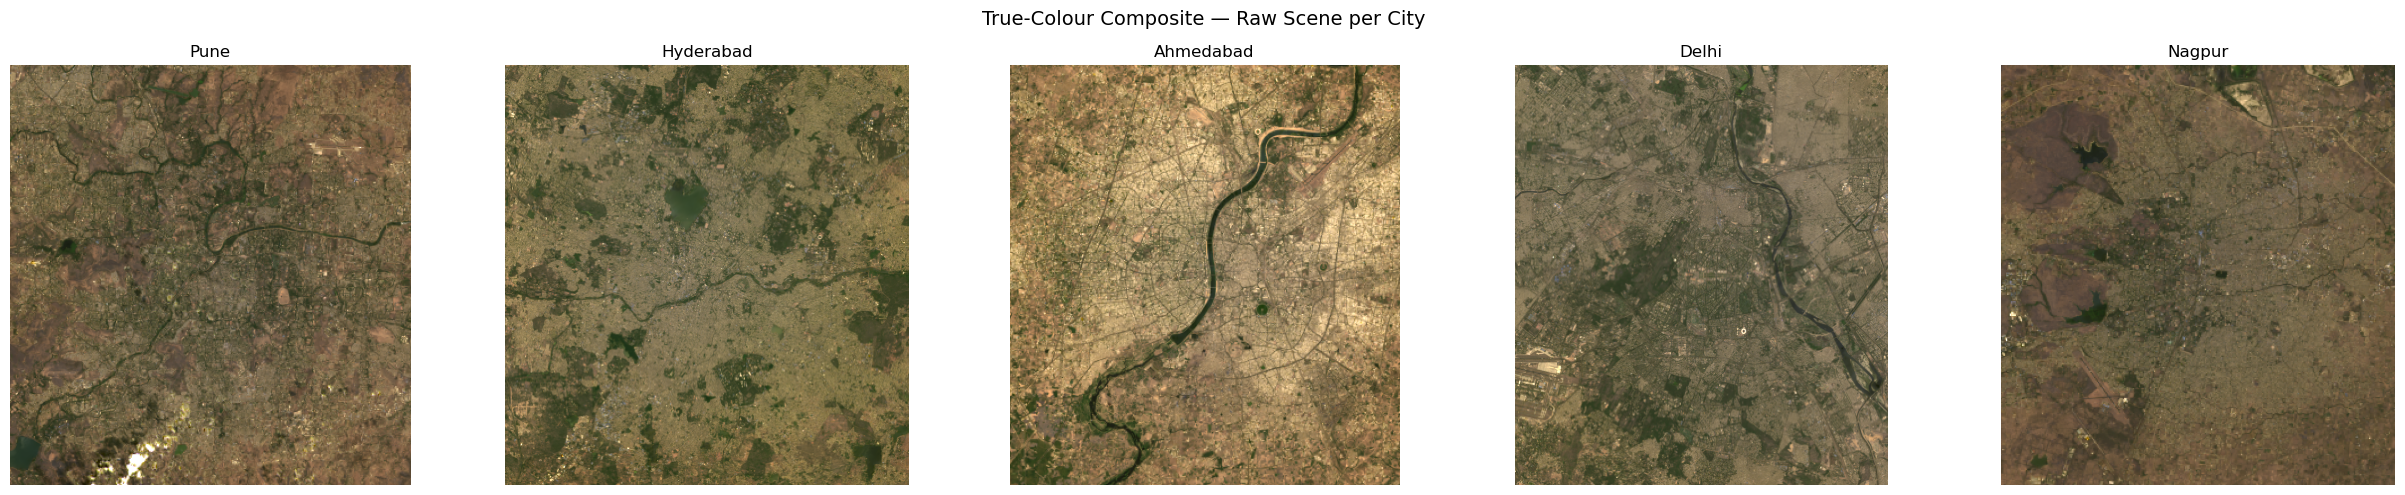

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for ax, (city, (image, region)) in zip(axes, raw_images.items()):
    rgb = image.select(['SR_B4', 'SR_B3', 'SR_B2'])  # Red, Green, Blue (unscaled DN)
    rgb_scaled = rgb.multiply(0.0000275).add(-0.2)     # apply SR scaling factor

    arr = geemap.ee_to_numpy(rgb_scaled, region=region, scale=60)  # scale=60 for faster preview
    arr = np.clip(arr * 3.5, 0, 1)  # simple brightness stretch for visibility

    ax.imshow(arr)
    ax.set_title(city)
    ax.axis('off')

plt.suptitle("True-Colour Composite — Raw Scene per City", fontsize=14)
plt.tight_layout()
plt.show()

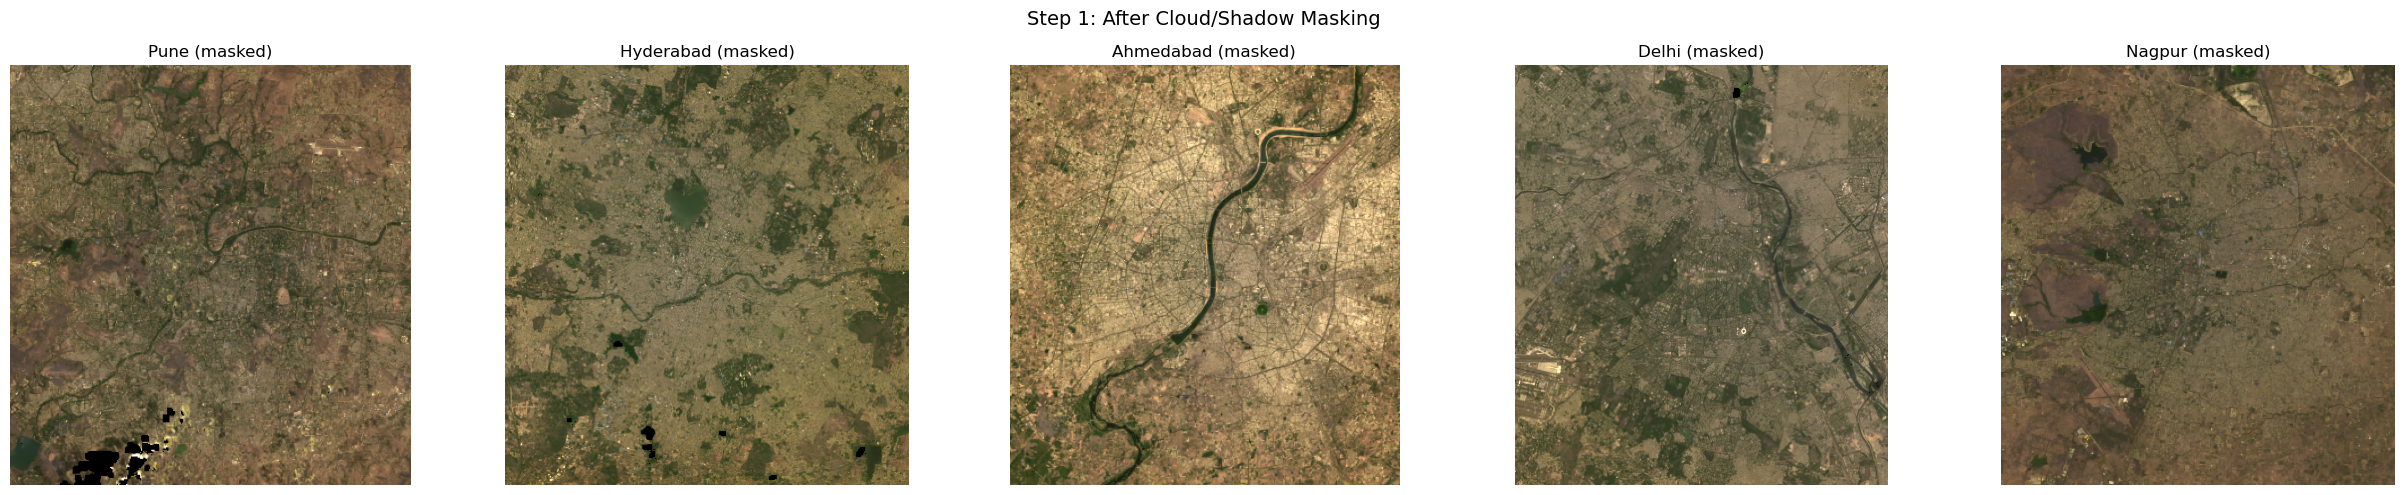

In [9]:
def mask_clouds(image):
    qa = image.select('QA_PIXEL')
    cloud_bit = 1 << 3
    shadow_bit = 1 << 4
    mask = qa.bitwiseAnd(cloud_bit).eq(0).And(qa.bitwiseAnd(shadow_bit).eq(0))
    return image.updateMask(mask)

def mask_and_scale(image):
    """Cloud-mask, then apply Collection 2 scaling so bands are true reflectance before any index math."""
    masked = mask_clouds(image)
    optical = masked.select('SR_B.').multiply(0.0000275).add(-0.2)
    return masked.addBands(optical, None, True)  # overwrite SR_ bands with scaled versions

masked_images = {}

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for ax, (city, (image, region)) in zip(axes, raw_images.items()):
    masked = mask_and_scale(image)
    masked_images[city] = (masked, region)

    rgb = masked.select(['SR_B4', 'SR_B3', 'SR_B2'])  # already scaled now, no need to re-scale here
    arr = geemap.ee_to_numpy(rgb, region=region, scale=60)
    arr = np.clip(arr * 3.5, 0, 1)

    ax.imshow(arr)
    ax.set_title(f"{city} (masked)")
    ax.axis('off')

plt.suptitle("Step 1: After Cloud/Shadow Masking", fontsize=14)
plt.tight_layout()
plt.show()

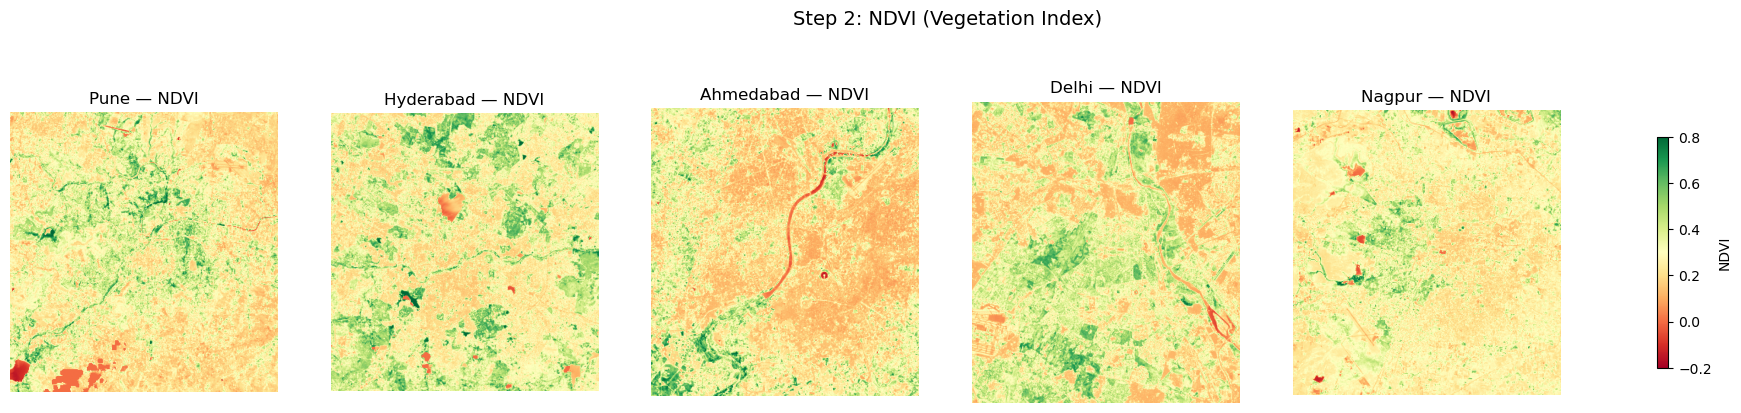

In [10]:
ndvi_images = {}

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for ax, (city, (image, region)) in zip(axes, masked_images.items()):
    ndvi = image.normalizedDifference(['SR_B5', 'SR_B4']).rename('ndvi')
    ndvi_images[city] = ndvi

    arr = geemap.ee_to_numpy(ndvi, region=region, scale=60)[:, :, 0]

    im = ax.imshow(arr, cmap='RdYlGn', vmin=-0.2, vmax=0.8)
    ax.set_title(f"{city} — NDVI")
    ax.axis('off')

plt.suptitle("Step 2: NDVI (Vegetation Index)", fontsize=14)
fig.colorbar(im, ax=axes, shrink=0.6, label='NDVI')
plt.show()

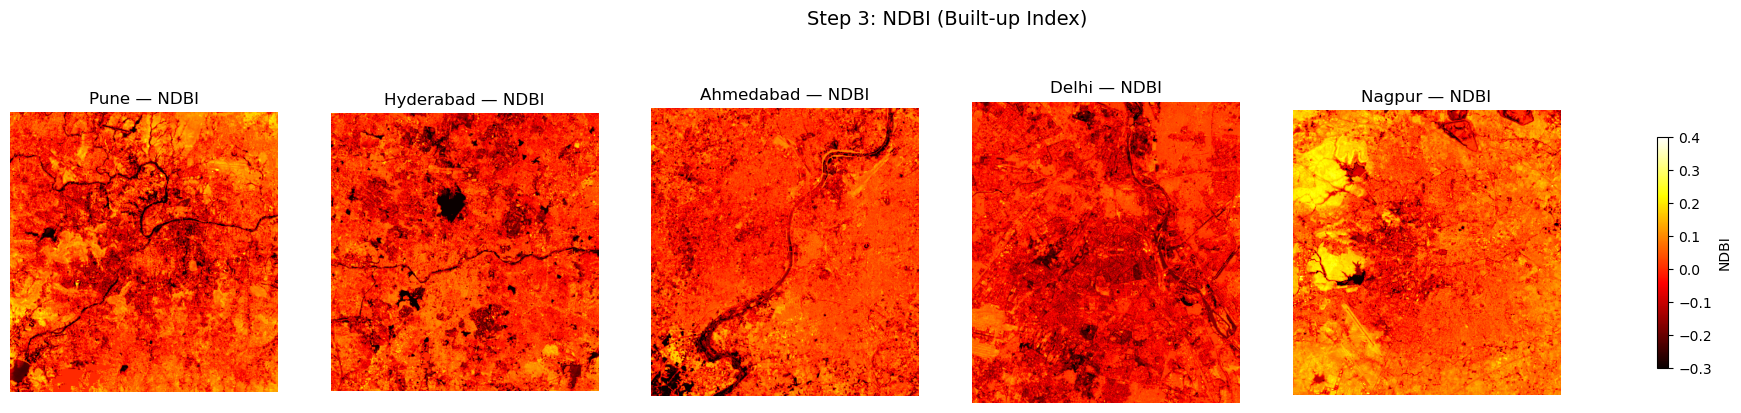

In [11]:
ndbi_images = {}

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for ax, (city, (image, region)) in zip(axes, masked_images.items()):
    ndbi = image.normalizedDifference(['SR_B6', 'SR_B5']).rename('ndbi')
    ndbi_images[city] = ndbi

    arr = geemap.ee_to_numpy(ndbi, region=region, scale=60)[:, :, 0]

    im = ax.imshow(arr, cmap='hot', vmin=-0.3, vmax=0.4)
    ax.set_title(f"{city} — NDBI")
    ax.axis('off')

plt.suptitle("Step 3: NDBI (Built-up Index)", fontsize=14)
fig.colorbar(im, ax=axes, shrink=0.6, label='NDBI')
plt.show()

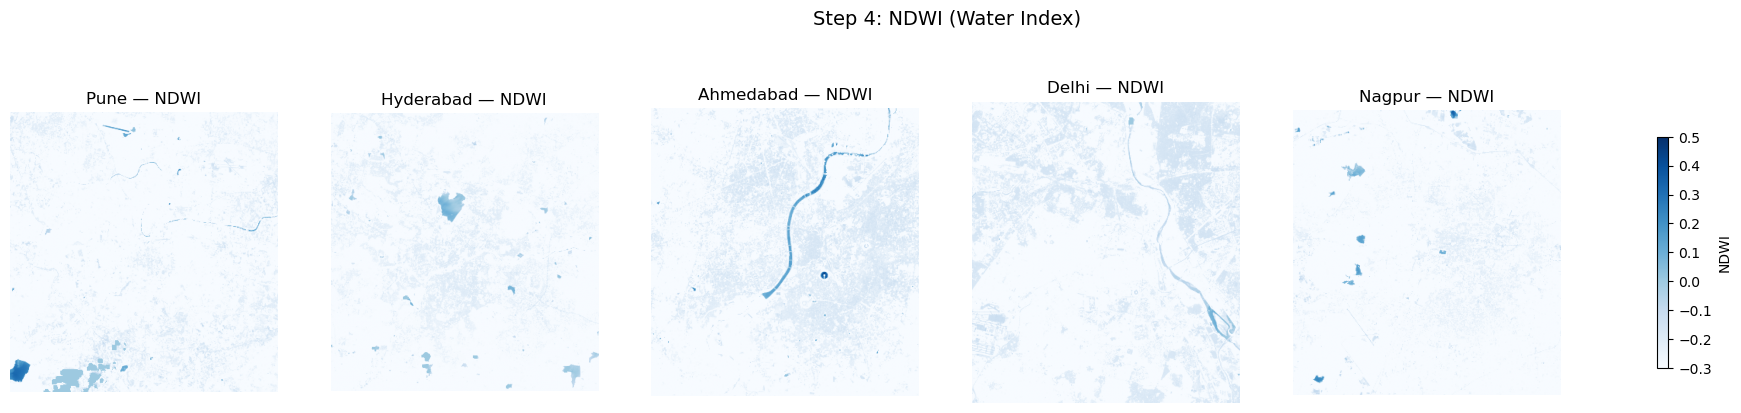

In [12]:
ndwi_images = {}

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for ax, (city, (image, region)) in zip(axes, masked_images.items()):
    ndwi = image.normalizedDifference(['SR_B3', 'SR_B5']).rename('ndwi')
    ndwi_images[city] = ndwi

    arr = geemap.ee_to_numpy(ndwi, region=region, scale=60)[:, :, 0]

    im = ax.imshow(arr, cmap='Blues', vmin=-0.3, vmax=0.5)
    ax.set_title(f"{city} — NDWI")
    ax.axis('off')

plt.suptitle("Step 4: NDWI (Water Index)", fontsize=14)
fig.colorbar(im, ax=axes, shrink=0.6, label='NDWI')
plt.show()

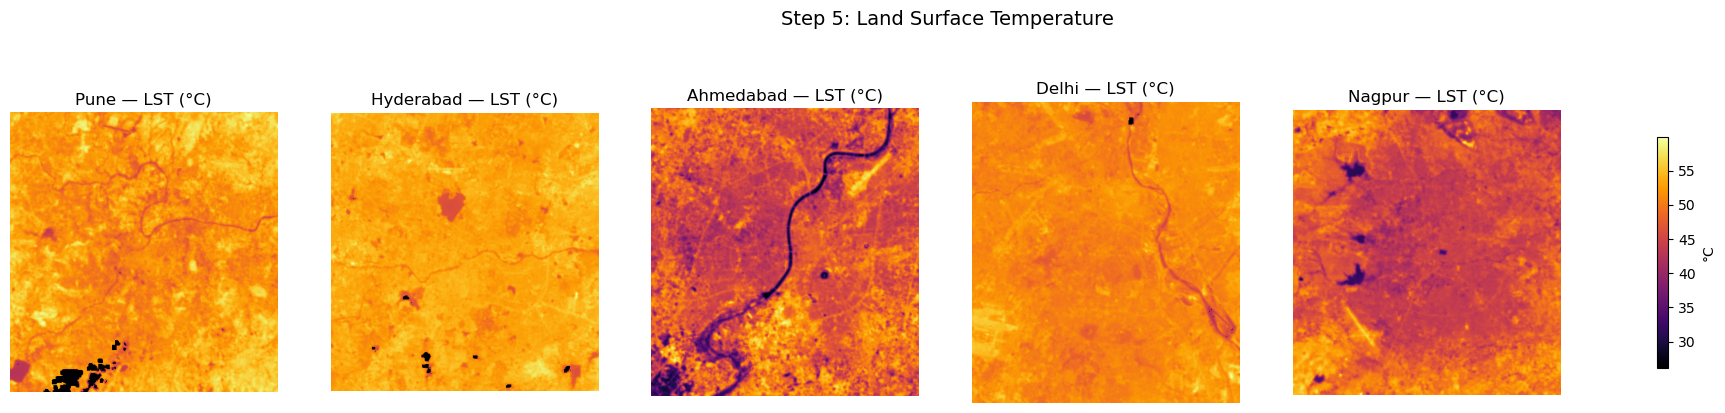

Pune: computed, check plot above for plausible 20-50°C range
Hyderabad: computed, check plot above for plausible 20-50°C range
Ahmedabad: computed, check plot above for plausible 20-50°C range
Delhi: computed, check plot above for plausible 20-50°C range
Nagpur: computed, check plot above for plausible 20-50°C range


In [13]:
lst_images = {}

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for ax, (city, (image, region)) in zip(axes, masked_images.items()):
    lst = image.select('ST_B10').multiply(0.00341802).add(149.0).subtract(273.15).rename('temp_c')
    lst_images[city] = lst

    arr = geemap.ee_to_numpy(lst, region=region, scale=60)[:, :, 0]

    im = ax.imshow(arr, cmap='inferno')
    ax.set_title(f"{city} — LST (°C)")
    ax.axis('off')

plt.suptitle("Step 5: Land Surface Temperature", fontsize=14)
fig.colorbar(im, ax=axes, shrink=0.6, label='°C')
plt.show()

# Quick sanity check: print temp range per city
for city, lst in lst_images.items():
    print(f"{city}: computed, check plot above for plausible 20-50°C range")

In [14]:
def extract_city_df(city, image, region, n_pixels=50000, batch_size=4000, seed=42):
    ndvi = image.normalizedDifference(['SR_B5', 'SR_B4']).rename('ndvi')
    ndbi = image.normalizedDifference(['SR_B6', 'SR_B5']).rename('ndbi')
    ndwi = image.normalizedDifference(['SR_B3', 'SR_B5']).rename('ndwi')
    temp_c = image.select('ST_B10').multiply(0.00341802).add(149.0).subtract(273.15).rename('temp_c')

    stacked = ee.Image.cat([temp_c, ndvi, ndbi, ndwi])

    all_rows = []
    n_batches = int(np.ceil(n_pixels / batch_size))

    for i in range(n_batches):
        sample = stacked.sample(
            region=region,
            scale=30,
            numPixels=batch_size,
            seed=seed + i,
            geometries=True
        )
        features = sample.getInfo()['features']
        for f in features:
            props = f['properties']
            coords = f['geometry']['coordinates']
            all_rows.append({
                "x_m": coords[0],
                "y_m": coords[1],
                "temp_c": props.get("temp_c"),
                "ndvi": props.get("ndvi"),
                "ndbi": props.get("ndbi"),
                "ndwi": props.get("ndwi"),
            })
        print(f"  {city} batch {i+1}/{n_batches} -> {len(features)} pixels")

    df = pd.DataFrame(all_rows).dropna().drop_duplicates(subset=["x_m", "y_m"])
    df["city"] = city
    return df

city_dfs = {}
for city, (image, region) in masked_images.items():
    print(f"Extracting {city}...")
    city_dfs[city] = extract_city_df(city, image, region)
    print(f"  -> {len(city_dfs[city])} total rows\n")

Extracting Pune...
  Pune batch 1/13 -> 3954 pixels
  Pune batch 2/13 -> 3960 pixels
  Pune batch 3/13 -> 3964 pixels
  Pune batch 4/13 -> 3954 pixels
  Pune batch 5/13 -> 3951 pixels
  Pune batch 6/13 -> 3956 pixels
  Pune batch 7/13 -> 3961 pixels
  Pune batch 8/13 -> 3956 pixels
  Pune batch 9/13 -> 3955 pixels
  Pune batch 10/13 -> 3946 pixels
  Pune batch 11/13 -> 3956 pixels
  Pune batch 12/13 -> 3965 pixels
  Pune batch 13/13 -> 3968 pixels
  -> 51446 total rows

Extracting Hyderabad...
  Hyderabad batch 1/13 -> 3994 pixels
  Hyderabad batch 2/13 -> 3992 pixels
  Hyderabad batch 3/13 -> 3991 pixels
  Hyderabad batch 4/13 -> 3987 pixels
  Hyderabad batch 5/13 -> 3989 pixels
  Hyderabad batch 6/13 -> 3989 pixels
  Hyderabad batch 7/13 -> 3997 pixels
  Hyderabad batch 8/13 -> 3992 pixels
  Hyderabad batch 9/13 -> 3992 pixels
  Hyderabad batch 10/13 -> 3995 pixels
  Hyderabad batch 11/13 -> 3984 pixels
  Hyderabad batch 12/13 -> 3986 pixels
  Hyderabad batch 13/13 -> 3991 pixels
  -

In [15]:
master_df = pd.concat(city_dfs.values(), ignore_index=True)
master_df.to_csv("master_df.csv", index=False)

print(f"Total rows: {len(master_df)}")
master_df.groupby("city").agg(
    rows=("temp_c", "count"),
    mean_temp=("temp_c", "mean"),
    mean_ndvi=("ndvi", "mean"),
    mean_ndbi=("ndbi", "mean"),
    mean_ndwi=("ndwi", "mean"),
)

Total rows: 259298


,rows,mean_temp,mean_ndvi,mean_ndbi,mean_ndwi
city,,,,,
Ahmedabad,51999,46.578366,0.248318,-0.007586,-0.316917
Delhi,51974,38.984478,0.296961,-0.051809,-0.324541
Hyderabad,51879,41.310174,0.329312,-0.029963,-0.356436
Nagpur,52000,46.282439,0.279676,0.045689,-0.343880
Pune,51446,46.612945,0.289869,-0.009453,-0.350743


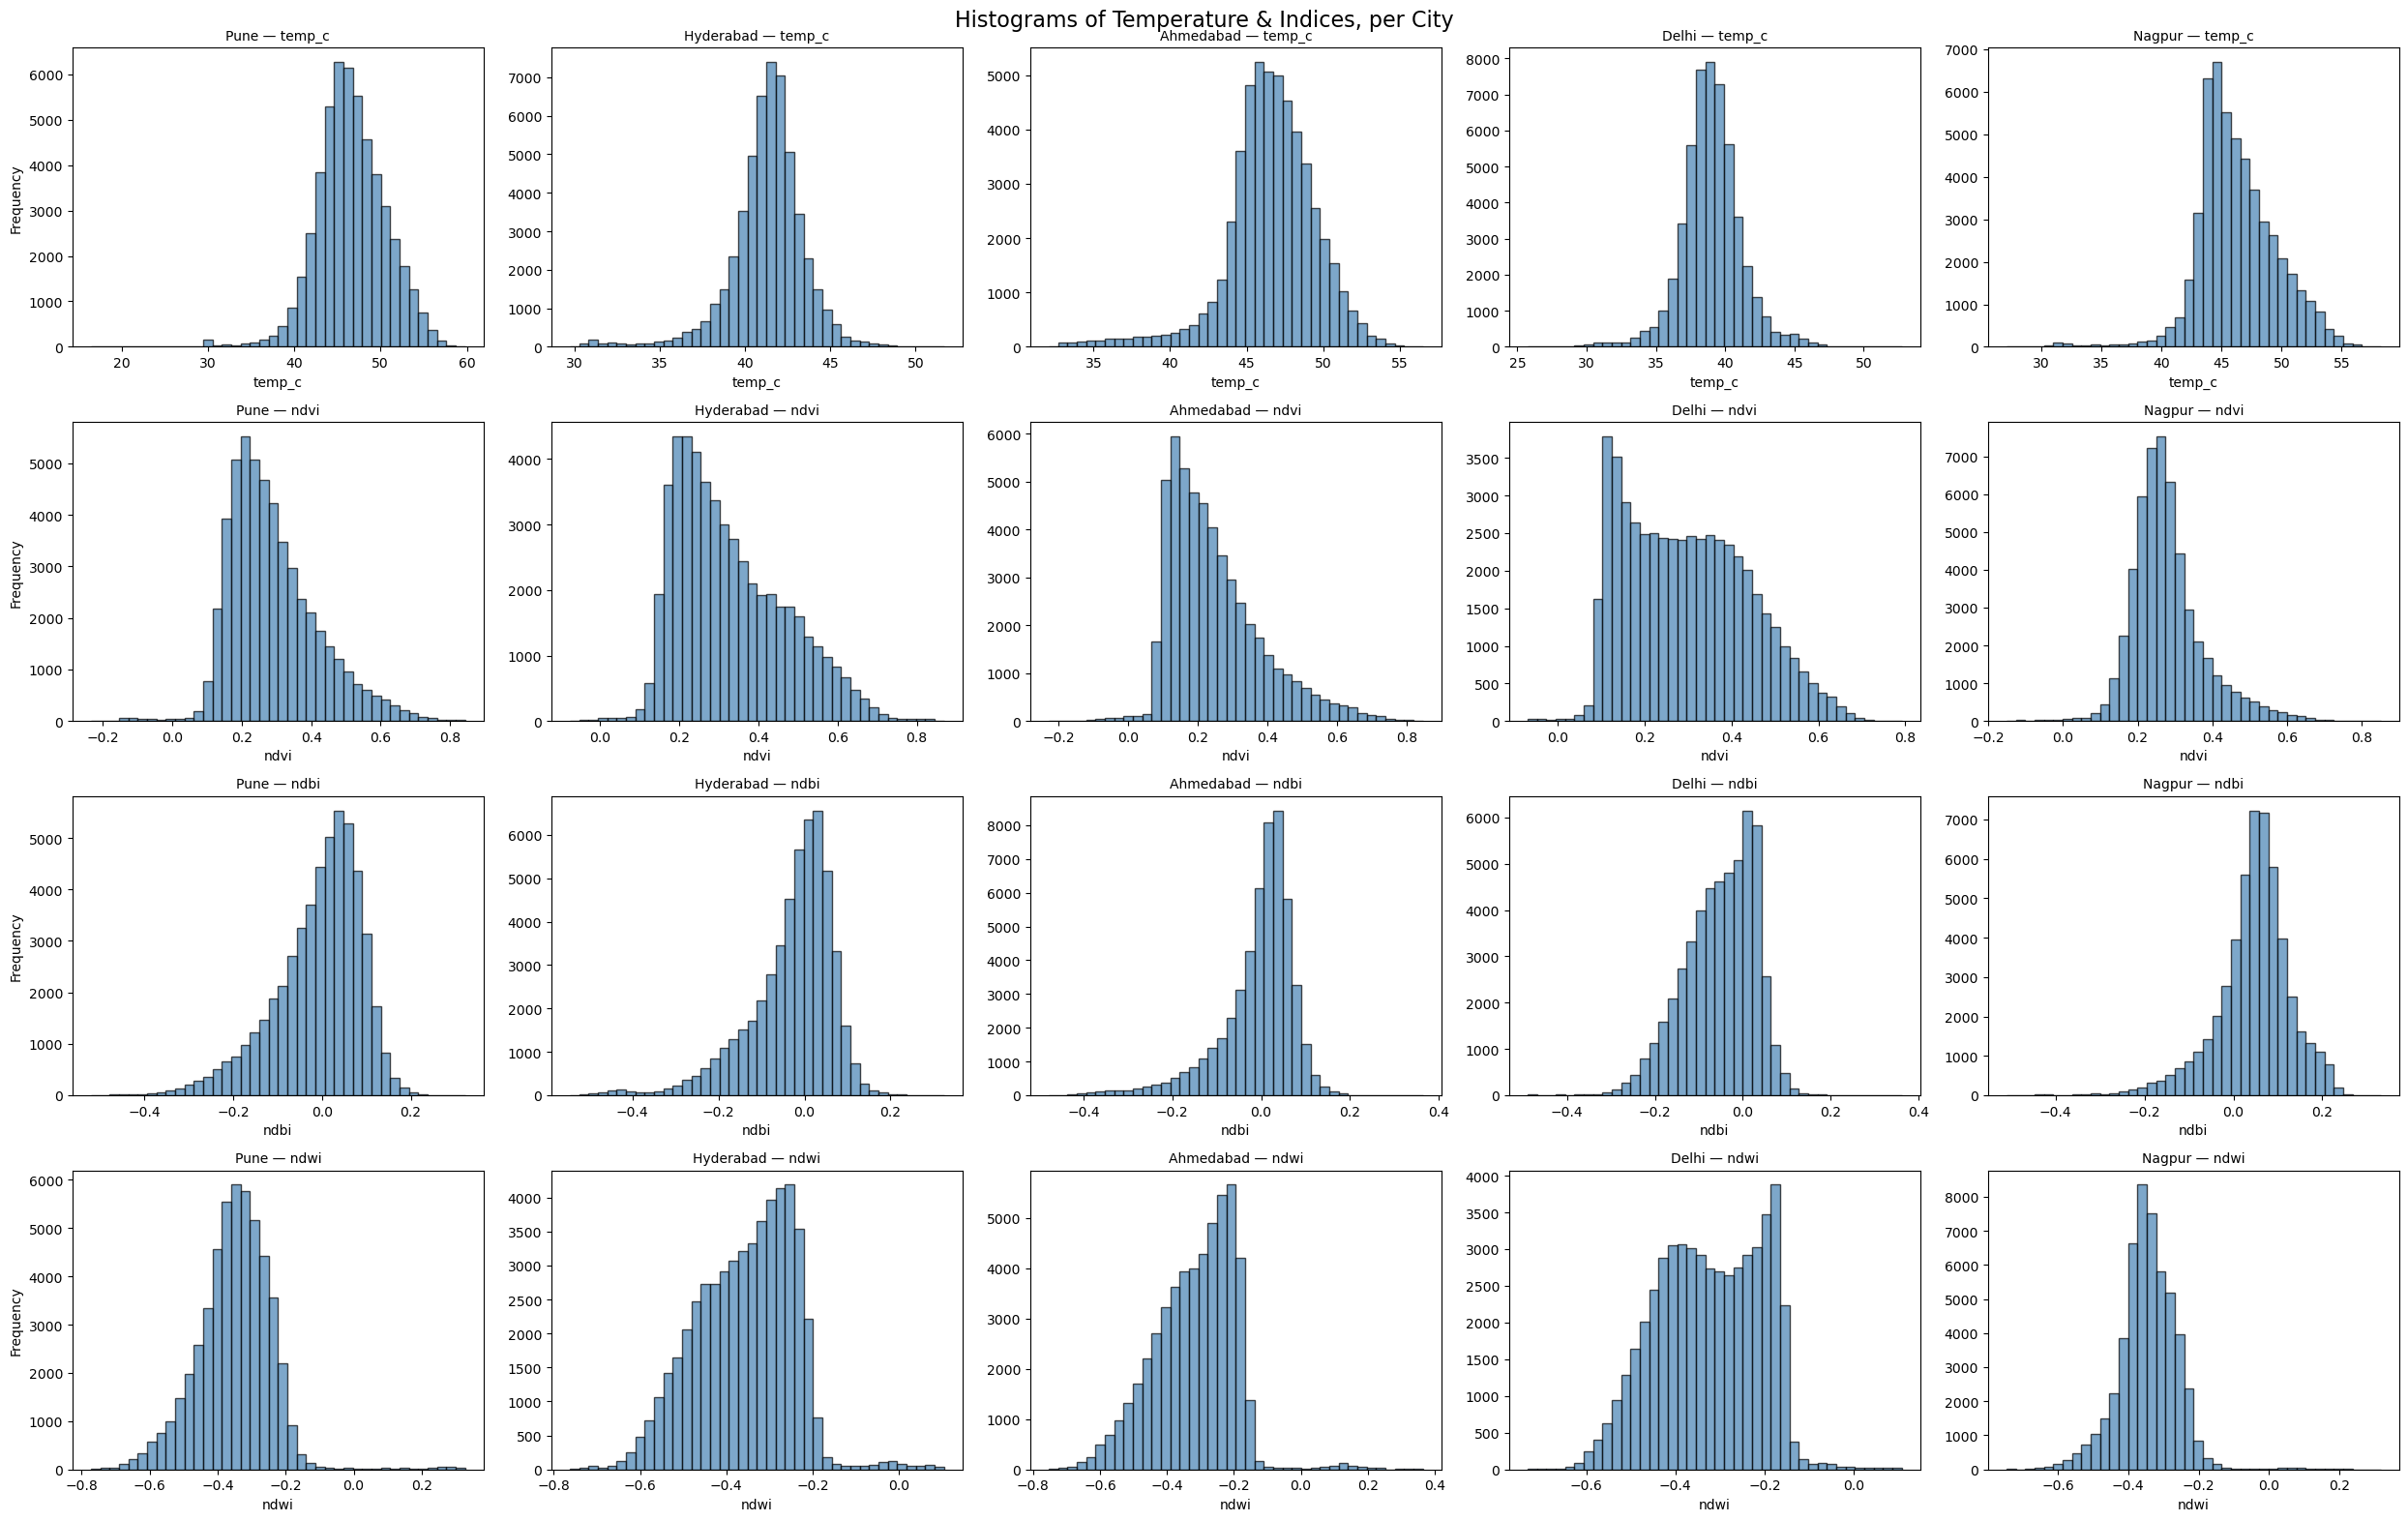

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

master_df = pd.read_csv("master_df.csv")
cities = master_df["city"].unique()
variables = ["temp_c", "ndvi", "ndbi", "ndwi"]

fig, axes = plt.subplots(len(variables), len(cities), figsize=(25, 16))

for i, var in enumerate(variables):
    for j, city in enumerate(cities):
        data = master_df[master_df["city"] == city][var]
        axes[i, j].hist(data, bins=40, color='steelblue', edgecolor='black', alpha=0.7)
        axes[i, j].set_title(f"{city} — {var}", fontsize=10)
        axes[i, j].set_xlabel(var)
        if j == 0:
            axes[i, j].set_ylabel("Frequency")

plt.suptitle("Histograms of Temperature & Indices, per City", fontsize=16)
plt.tight_layout()
plt.show()

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

df = pd.read_csv("master_df.csv")

print("Shape (rows, columns):", df.shape)
print()
print(df.head())
print()
print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print()
print("Rows per city:")
print(df["city"].value_counts())

# Type of each variable
types = pd.DataFrame({
    "variable": ["x_m", "y_m", "temp_c", "ndvi", "ndbi", "ndwi", "city"],
    "type": ["numerical", "numerical", "numerical", "numerical",
             "numerical", "numerical", "categorical"]
})
print()
print(types)

Shape (rows, columns): (259298, 7)

         x_m        y_m     temp_c      ndvi      ndbi      ndwi  city
0  73.762635  18.477641  53.166624  0.288194  0.125048 -0.366681  Pune
1  73.878052  18.542862  37.829968  0.411834 -0.245797 -0.402521  Pune
2  73.821789  18.479582  42.594688  0.247850 -0.038873 -0.285491  Pune
3  73.775532  18.505863  50.548420  0.272638  0.097207 -0.353918  Pune
4  73.821372  18.533453  43.749978  0.390335 -0.039013 -0.422057  Pune

Missing values in each column:
x_m       0
y_m       0
temp_c    0
ndvi      0
ndbi      0
ndwi      0
city      0
dtype: int64

Duplicate rows: 0

Rows per city:
city
Nagpur       52000
Ahmedabad    51999
Delhi        51974
Hyderabad    51879
Pune         51446
Name: count, dtype: int64

  variable         type
0      x_m    numerical
1      y_m    numerical
2   temp_c    numerical
3     ndvi    numerical
4     ndbi    numerical
5     ndwi    numerical
6     city  categorical


In [18]:
# Start with everything as bare, then overwrite using the rules.
# The last rule written wins (water > vegetation > built-up > bare).
df["landcover"] = "bare"
df.loc[df["ndbi"] > 0, "landcover"] = "built-up"
df.loc[df["ndvi"] > 0.3, "landcover"] = "vegetation"
df.loc[df["ndwi"] > 0.1, "landcover"] = "water"

print(df["landcover"].value_counts())
print()
print(pd.crosstab(df["city"], df["landcover"]))

df.to_csv("master_clean.csv", index=False)

landcover
built-up      118147
vegetation    101437
bare           38952
water            762
Name: count, dtype: int64

landcover   bare  built-up  vegetation  water
city                                         
Ahmedabad   9071     27895       14663    370
Delhi      12415     15180       24376      3
Hyderabad   7805     18243       25827      4
Nagpur      2816     32526       16545    113
Pune        6845     24303       20026    272


In [ ]:
population_size = len(df)

sample_df = df.groupby("city").sample(n=1000, random_state=42)
sample_df = sample_df.reset_index(drop=True)

print("Population size:", population_size)
print("Sample size    :", len(sample_df))
print()
print(sample_df["city"].value_counts())

# Bias check: is the sample mean close to the population mean?
compare = pd.DataFrame({
    "population_mean": df.groupby("city")["temp_c"].mean(),
    "sample_mean": sample_df.groupby("city")["temp_c"].mean()
})
compare["difference"] = compare["sample_mean"] - compare["population_mean"]
print()
print(compare.round(3))

sample_df.to_csv("sample_df.csv", index=False)

Population size: 259298
Sample size    : 5000

city
Ahmedabad    1000
Delhi        1000
Hyderabad    1000
Nagpur       1000
Pune         1000
Name: count, dtype: int64

           population_mean  sample_mean  difference
city                                               
Ahmedabad           46.578       46.662       0.084
Delhi               38.984       38.931      -0.054
Hyderabad           41.310       41.266      -0.044
Nagpur              46.282       46.318       0.035
Pune                46.613       46.779       0.166


Population mean            : 46.613
Mean of the sample means   : 46.637
Population std / sqrt(30)  : 0.722
Std of the sample means    : 0.739


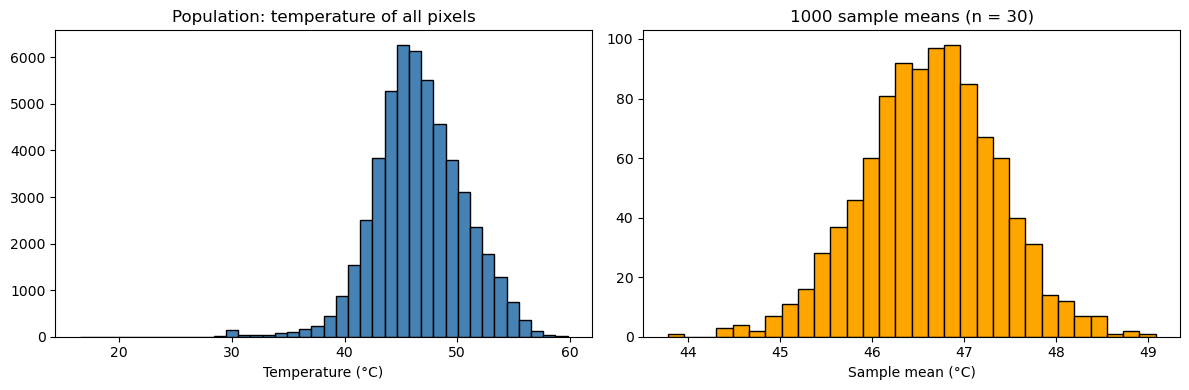

In [ ]:
np.random.seed(42)

population = df[df["city"] == "Pune"]["temp_c"]   # change city if you like

sample_means = []
for i in range(1000):
    small_sample = population.sample(n=30)
    sample_means.append(small_sample.mean())

sample_means = np.array(sample_means)

print("Population mean            :", round(population.mean(), 3))
print("Mean of the sample means   :", round(sample_means.mean(), 3))
print("Population std / sqrt(30)  :", round(population.std() / np.sqrt(30), 3))
print("Std of the sample means    :", round(sample_means.std(), 3))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(population, bins=40, color="steelblue", edgecolor="black")
plt.title("Population: temperature of all pixels")
plt.xlabel("Temperature (°C)")

plt.subplot(1, 2, 2)
plt.hist(sample_means, bins=30, color="orange", edgecolor="black")
plt.title("1000 sample means (n = 30)")
plt.xlabel("Sample mean (°C)")

plt.tight_layout()
plt.show()

Descrpitive Analysis

In [22]:
cities = list(sample_df["city"].unique())

# Temperature summary for each city
summary = sample_df.groupby("city")["temp_c"].agg(["mean", "median", "std"])
summary["Q1"] = sample_df.groupby("city")["temp_c"].quantile(0.25)
summary["Q3"] = sample_df.groupby("city")["temp_c"].quantile(0.75)
summary["IQR"] = summary["Q3"] - summary["Q1"]
print("Temperature (°C) by city:")
print(summary.round(2))

# Summary of all four variables together
cols = ["temp_c", "ndvi", "ndbi", "ndwi"]
overall = pd.DataFrame({
    "mean": sample_df[cols].mean(),
    "median": sample_df[cols].median(),
    "std": sample_df[cols].std(),
    "IQR": sample_df[cols].quantile(0.75) - sample_df[cols].quantile(0.25)
})
print()
print("All cities together:")
print(overall.round(3))

Temperature (°C) by city:
            mean  median   std     Q1     Q3   IQR
city                                              
Ahmedabad  46.66   46.79  3.02  45.25  48.46  3.21
Delhi      38.93   38.98  2.18  37.79  40.12  2.33
Hyderabad  41.27   41.43  2.33  40.27  42.51  2.23
Nagpur     46.32   45.94  3.35  44.22  48.42  4.20
Pune       46.78   46.69  3.84  44.21  49.12  4.91

All cities together:
          mean  median    std    IQR
temp_c  43.991  44.082  4.443  6.580
ndvi     0.290   0.265  0.130  0.173
ndbi    -0.010   0.007  0.094  0.114
ndwi    -0.340  -0.339  0.109  0.149


In [ ]:
Confidence Interval for Mean Temperature

95% confidence interval for mean temperature
Ahmedabad : mean = 46.66  CI = ( 46.47 , 46.85 )
Delhi : mean = 38.93  CI = ( 38.8 , 39.07 )
Hyderabad : mean = 41.27  CI = ( 41.12 , 41.41 )
Nagpur : mean = 46.32  CI = ( 46.11 , 46.53 )
Pune : mean = 46.78  CI = ( 46.54 , 47.02 )


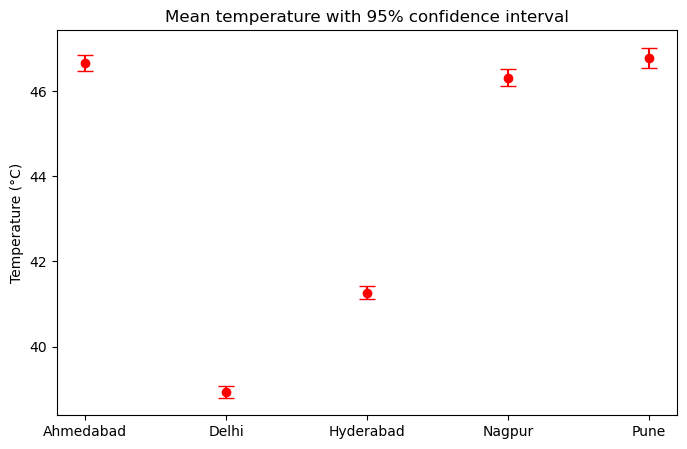

In [23]:
means = []
margins = []

print("95% confidence interval for mean temperature")
for city in cities:
    x = sample_df[sample_df["city"] == city]["temp_c"]
    n = len(x)
    mean = x.mean()
    sd = x.std()

    se = sd / np.sqrt(n)                  
    t_value = stats.t.ppf(0.975, n - 1)   
    margin = t_value * se

    lower = mean - margin
    upper = mean + margin
    print(city, ": mean =", round(mean, 2), " CI = (", round(lower, 2), ",", round(upper, 2), ")")

    means.append(mean)
    margins.append(margin)

plt.figure(figsize=(8, 5))
plt.errorbar(cities, means, yerr=margins, fmt="o", capsize=6, color="red")
plt.title("Mean temperature with 95% confidence interval")
plt.ylabel("Temperature (°C)")
plt.show()

In [ ]:
Correlation Plot


In [24]:
print("Correlation of temperature with each index")
print("-" * 55)
for col in ["ndvi", "ndbi", "ndwi"]:
    r, p1 = stats.pearsonr(sample_df[col], sample_df["temp_c"])
    rho, p2 = stats.spearmanr(sample_df[col], sample_df["temp_c"])
    print(col, ": Pearson r =", round(r, 3), "(p =", round(p1, 4), ")",
          "| Spearman =", round(rho, 3), "(p =", round(p2, 4), ")")

print()
print("Covariance matrix:")
print(sample_df[["temp_c", "ndvi", "ndbi", "ndwi"]].cov().round(4))

Correlation of temperature with each index
-------------------------------------------------------
ndvi : Pearson r = -0.314 (p = 0.0 ) | Spearman = -0.292 (p = 0.0 )
ndbi : Pearson r = 0.614 (p = 0.0 ) | Spearman = 0.605 (p = 0.0 )
ndwi : Pearson r = 0.077 (p = 0.0 ) | Spearman = 0.111 (p = 0.0 )

Covariance matrix:
         temp_c    ndvi    ndbi    ndwi
temp_c  19.7362 -0.1817  0.2578  0.0377
ndvi    -0.1817  0.0169 -0.0080 -0.0135
ndbi     0.2578 -0.0080  0.0089  0.0047
ndwi     0.0377 -0.0135  0.0047  0.0120


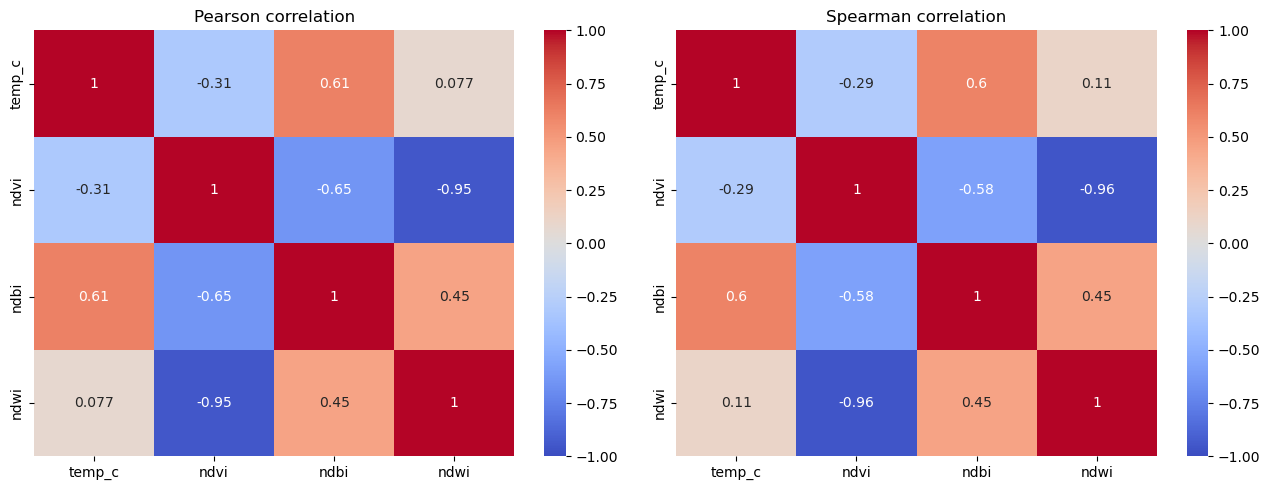

In [25]:
corr_p = sample_df[["temp_c", "ndvi", "ndbi", "ndwi"]].corr(method="pearson")
corr_s = sample_df[["temp_c", "ndvi", "ndbi", "ndwi"]].corr(method="spearman")

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
sns.heatmap(corr_p, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson correlation")

plt.subplot(1, 2, 2)
sns.heatmap(corr_s, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation")

plt.tight_layout()
plt.show()

One-sample Z-test and t-test

In [26]:
city_name = "Pune"     
claim = 40              
# H0: mean temperature = claim
# H1: mean temperature != claim
x = sample_df[sample_df["city"] == city_name]["temp_c"]
n = len(x)
mean = x.mean()
sd = x.std()

# Z-test
z = (mean - claim) / (sd / np.sqrt(n))
p_z = 2 * stats.norm.sf(abs(z))

# t-test
t_stat, p_t = stats.ttest_1samp(x, claim)

print("City:", city_name, "| n =", n, "| sample mean =", round(mean, 2))
print("Z-test: z =", round(z, 3), " p-value =", round(p_z, 6))
print("t-test: t =", round(t_stat, 3), " p-value =", round(p_t, 6))

if p_t < 0.05:
    print("Reject H0: the mean temperature is significantly different from", claim)
else:
    print("Fail to reject H0: no significant difference from", claim)

City: Pune | n = 1000 | sample mean = 46.78
Z-test: z = 55.769  p-value = 0.0
t-test: t = 55.769  p-value = 0.0
Reject H0: the mean temperature is significantly different from 40


t test for build-up vs Vegetation


Built-up   : n = 2277  mean = 46.17
Vegetation : n = 1987  mean = 42.27

t = 32.68  p-value = 0.0
Difference in means = 3.9 °C
Reject H0: built-up and vegetation temperatures differ significantly


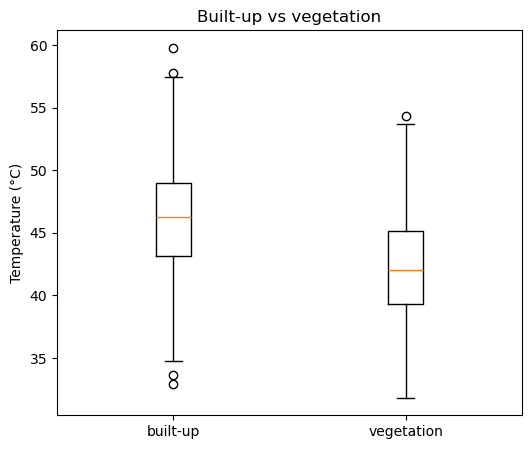

In [27]:
# H0: mean temperature of bu ilt-up = mean temperature of vegetation
# H1: they are different
builtup = sample_df[sample_df["landcover"] == "built-up"]["temp_c"]
veg = sample_df[sample_df["landcover"] == "vegetation"]["temp_c"]

print("Built-up   : n =", len(builtup), " mean =", round(builtup.mean(), 2))
print("Vegetation : n =", len(veg), " mean =", round(veg.mean(), 2))

t_stat, p_value = stats.ttest_ind(builtup, veg, equal_var=False)
print()
print("t =", round(t_stat, 3), " p-value =", round(p_value, 6))
print("Difference in means =", round(builtup.mean() - veg.mean(), 2), "°C")

if p_value < 0.05:
    print("Reject H0: built-up and vegetation temperatures differ significantly")
else:
    print("Fail to reject H0: no significant difference")

plt.figure(figsize=(6, 5))
plt.boxplot([builtup, veg])
plt.xticks([1, 2], ["built-up", "vegetation"])
plt.ylabel("Temperature (°C)")
plt.title("Built-up vs vegetation")
plt.show()

One-way ANOVA across cities

F-statistic = 1470.607
p-value     = 0.0
Reject H0: at least one city has a different mean temperature


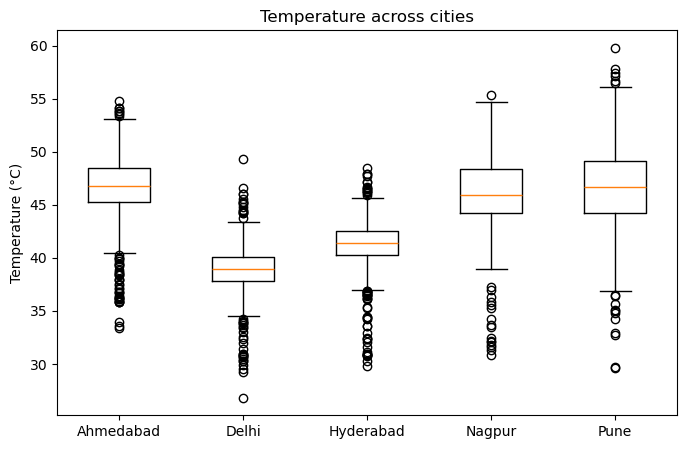

In [28]:
# H0: all cities have the same mean temperature
# H1: at least one city has a different mean temperature
groups = []
for city in cities:
    groups.append(sample_df[sample_df["city"] == city]["temp_c"])

f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic =", round(f_stat, 3))
print("p-value     =", round(p_value, 6))

if p_value < 0.05:
    print("Reject H0: at least one city has a different mean temperature")
else:
    print("Fail to reject H0: no significant difference between cities")

plt.figure(figsize=(8, 5))
plt.boxplot(groups)
plt.xticks(range(1, len(cities) + 1), cities)
plt.ylabel("Temperature (°C)")
plt.title("Temperature across cities")
plt.show()

Simple linear regression (temp vs NDVI) with a held-out test set

In [29]:
# Split: 80% training, 20% testing
shuffled = sample_df.sample(frac=1, random_state=42).reset_index(drop=True)
split_point = int(0.8 * len(shuffled))
train = shuffled[:split_point]
test = shuffled[split_point:]

print("Training rows:", len(train), "| Test rows:", len(test))

# Function to calculate the evaluation metrics
def evaluate(actual, predicted):
    errors = actual - predicted
    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum(errors ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mae, mse, rmse, r2

# Fit the line on training data: temp_c = intercept + slope * ndvi
result = stats.linregress(train["ndvi"], train["temp_c"])
slope = result.slope
intercept = result.intercept

print()
print("Equation: temp_c =", round(intercept, 3), "+", round(slope, 3), "* ndvi")
print("Slope p-value:", result.pvalue)
print("A 0.1 increase in NDVI changes temperature by", round(slope * 0.1, 3), "°C")

# Predict on unseen test data
test_pred = intercept + slope * test["ndvi"]
mae, mse, rmse, r2 = evaluate(test["temp_c"], test_pred)

print()
print("Evaluation on test data:")
print("MAE  =", round(mae, 3))
print("MSE  =", round(mse, 3))
print("RMSE =", round(rmse, 3))
print("R²   =", round(r2, 3))

Training rows: 4000 | Test rows: 1000

Equation: temp_c = 47.16 + -10.953 * ndvi
Slope p-value: 1.425169210644332e-96
A 0.1 increase in NDVI changes temperature by -1.095 °C

Evaluation on test data:
MAE  = 3.441
MSE  = 18.43
RMSE = 4.293
R²   = 0.082


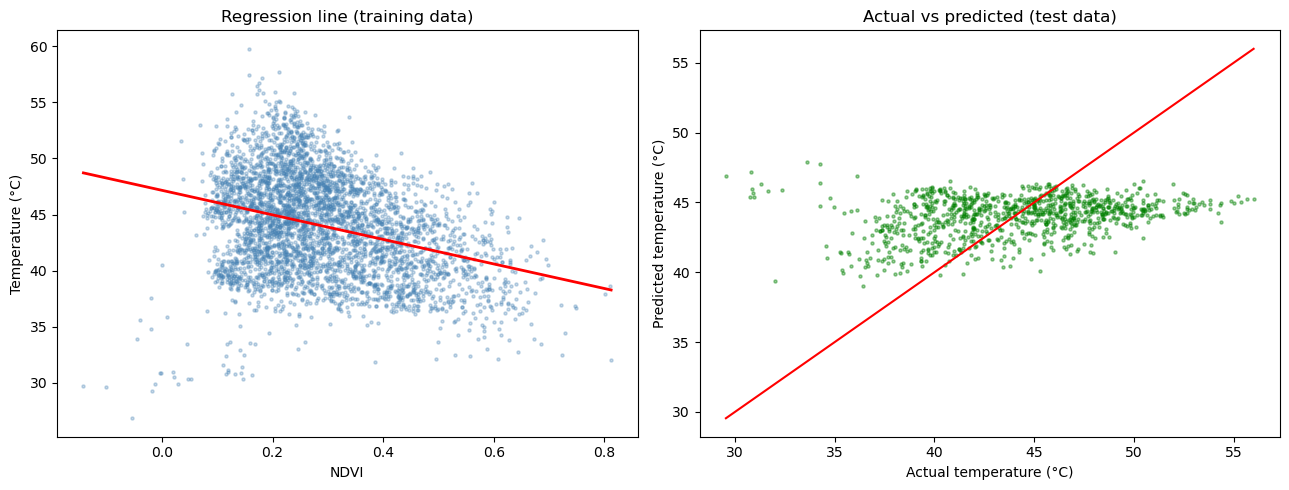

In [30]:
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.scatter(train["ndvi"], train["temp_c"], s=5, alpha=0.3, color="steelblue")
x_line = np.linspace(train["ndvi"].min(), train["ndvi"].max(), 100)
plt.plot(x_line, intercept + slope * x_line, color="red", linewidth=2)
plt.xlabel("NDVI")
plt.ylabel("Temperature (°C)")
plt.title("Regression line (training data)")

plt.subplot(1, 2, 2)
plt.scatter(test["temp_c"], test_pred, s=5, alpha=0.4, color="green")
plt.plot([test["temp_c"].min(), test["temp_c"].max()],
         [test["temp_c"].min(), test["temp_c"].max()], color="red")
plt.xlabel("Actual temperature (°C)")
plt.ylabel("Predicted temperature (°C)")
plt.title("Actual vs predicted (test data)")

plt.tight_layout()
plt.show()

Multiple linear regression (temp vs NDVI, NDBI, NDWI)

In [31]:
features = ["ndvi", "ndbi", "ndwi"]

X_train = sm.add_constant(train[features])
model = sm.OLS(train["temp_c"], X_train).fit()
print(model.summary())

# Predict on unseen test data
X_test = sm.add_constant(test[features])
test_pred2 = model.predict(X_test)

mae2, mse2, rmse2, r2_2 = evaluate(test["temp_c"], test_pred2)

print()
print("Comparison on test data")
print("                 MAE     MSE     RMSE    R²")
print("Simple (ndvi)  ", round(mae, 3), round(mse, 3), round(rmse, 3), round(r2, 3))
print("Multiple       ", round(mae2, 3), round(mse2, 3), round(rmse2, 3), round(r2_2, 3))

                            OLS Regression Results                            
Dep. Variable:                 temp_c   R-squared:                       0.568
Model:                            OLS   Adj. R-squared:                  0.568
Method:                 Least Squares   F-statistic:                     1754.
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:33:27   Log-Likelihood:                -9950.9
No. Observations:                4000   AIC:                         1.991e+04
Df Residuals:                    3996   BIC:                         1.993e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         38.1674      0.183    209.103      0.0